## Abstract

El crecimiento exponencial del número de satélites que orbitan la Tierra está convirtiendo el problema de mitigación de debris (desechos) espacial en uno cada vez más mayor, no obstante hay directrices internacionales que pretenden regular el debris poniendo un tiempo de órbita máximo, donde una vez el satélite termine la misión tiene un plazo máximo de 25 años para reentrar en la atmósfera. 

Este trabajo pretende analizar y observar si los satélites en órbita baja (LEO) que ya fueron lanzados y reentraron a la atmósfera, cumplieron o no con las directrices internacionales de mitigación de debris. Se tiene en cuenta tanto el tiempo en órbita como el punto del perigeo, ya que a partir de determinado punto de perigeo, la reentrada natural se vuelve un gran problema y su tiempo en órbita se podría extender desde décadas hasta milenios. 

Los datos con los que se realiza el trabajo son públicos y se han cogido del catálogo GCAT (General Catalog of Artificial Space Objects), filtrando los satélites tanto pequeños, ya que son los que suelen orbitar el LEO, como los que ya han reentrado, quedándonos un tamaños total muestral de $n=1248$. Se hace un análisis tanto del perigeo en órbitas LLEO/S, utilizando contrastes paramétricos, como del tiempo en órbita en años, utilizando contrastes tanto paramétricos como no paramétricos; además, se realiza un modelo de regresión para explicar el tiempo en órbita en años a través del perigeo, apogeo, la inclinación y el año en el que fue lanzado el CubeSat. 

Los resultados obtenidos nos muestran que prácticamente todos los CubeSats que fueron lanzados, cumplieron con las directrices de mitigación del debris espacial y que todos ellos lo hicieron de forma natural, es decir, su punto de perigeo fue significativamente menor de 600Km. Además, se termina viendo que el tiempo en órbita en años queda explicado con una variabilidad de 65.7% por las variables mencionadas anteriormente.

## Introducción

Está habiendo un crecimiento exponencial del número de satélites que orbitan la Tierra, este hecho se debe a 2 factores. Uno de ellos son las grandes empresas que se dedican a lanzar constelaciones como modelo de negocio (Starlink de SpaceX en casi cinco años ya ha lanzado 2388 satélites). Además, tenemos la "revolución" de los satélites pequeños que son bastante útiles para empresas, instituciones o incluso universidades, ya que pueden lanzar su propio satélite y hacer uso de él.

Se ha podido detectar que actualmente hay cerca de 30.000 objetos conocidos, y se dice conocidos ya que hay algunos que son tan pequeños que no se han podido detectar. Y estos, los satélites pequeños son los más numerosos. De esos 30.000 objetos, 18.000 están en órbitas LEO (Low Earth Orbit), lo que nos indica que son satélites pequeños ya que es donde suelen orbitar; pero, de esos 18.000, los que son satélites son solo 5963. Con todo esto, tenemos una masa total en órbitas LEO de 3524 toneladas. [LEO](https://danielmarin.naukas.com/2022/04/23/cuantos-objetos-hay-en-orbita-la-importancia-de-proteger-el-medioambiente-espacial/)

No obstante, hay directrices internacionales que regulan la basura espacial, los satélites que orbitan en órbitas LEO tienen que reentrar en la atmósfera en un plazo máximo de 25 años tras el fin de su misión. Con esto, hay que tener en cuenta de que a partir de los 600Km, el tiempo en órbita del satélite puede extenderse desde décadas hasta llegar a milenios.

Es por ello que, en este trabajo, voy a centrarme en este problema desde una perspectiva estadística. He cogido el dataset del catálogo GCAT (General Catalog of Artificial Space Objects), he filtrado los CubeSats (satélites de tamaño pequeño) que ya no están en órbita, han reentrado en la atmósfera, permitiéndome calcular el tiempo real en órbita de cada CubeSat. Y sobre esto, he planteado varias hipótesis, donde se estudia si realmente están en órbita el tiempo estipulado, si se pasan del punto de los 600Km, diferencias entre los tipos de CubeSats más frecuentes (1U, 3U, 6U), y por último he construido un modelo regresivo para ver qué variables explican el tiempo en órbita en años del satélite.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import math
from scipy.stats import chi2, norm, gamma, kstest, kruskal, mannwhitneyu
import numpy as np
import statsmodels.api as sm

In [ ]:
gcat = pd.read_csv("https://planet4589.org/space/gcat/tsv/cat/satcat.tsv", 
                   sep='\t', low_memory=False)
gcat_decay = gcat[
    (gcat["Type"].str.startswith("P", na=False)) & 
    (gcat["DDate"].notna() & gcat["DDate"].ne('-')) &
    (gcat["Bus"].str.contains(r"CubeSat|cubesat|\b1U\b|\b2U\b|\b3U\b|\b6U\b|\b12U\b", case=False, na=False))
].copy()

(1472, 42)

In [3]:
pd.set_option("display.max_columns", None)
gcat_decay.head(2)

,#JCAT,Satcat,Launch_Tag,Piece,Type,Name,PLName,LDate,Parent,SDate,Primary,DDate,Status,Dest,Owner,State,Manufacturer,Bus,Motor,Mass,MassFlag,DryMass,DryFlag,TotMass,TotFlag,Length,LFlag,Diameter,DFlag,Span,SpanFlag,Shape,ODate,Perigee,PF,Apogee,AF,Inc,IF,OpOrbit,OQUAL,AltNames
29484,S29484,29484,2006-041,2006-041F,P,HITSAT-OSCAR-59,HIT-SAT,2006 Sep 22,S29480,2006 Sep 22 2149,Earth,2008 Jun 18,R,-,HOKIT,J,HOKIT,Cubesat 1U,-,4,,4,,4,,0.2,,0.1,,0.2,,Box,2006 Sep 25,279,,668,,98.33,,LLEO/S,-,HO-59
29655,S29655,29655,2006-058,2006-058C,P,Genesat-1,Genesat-1,2006 Dec 16,S29654,2006 Dec 16 1220,Earth,2010 Aug 4,R,-,ARC,US,ARC/SCU,Cubesat 3U,-,3,,3,,3,,0.3,,0.1,,0.3,,Box,2006 Dec 18,413,,419,,40.03,,LLEO/I,-,-


In [4]:
## Transformamos a numéricos

gcat_decay["Mass"] = pd.to_numeric(gcat_decay["Mass"].astype(str).str.strip(), errors="coerce")
gcat_decay["Perigee"] = pd.to_numeric(gcat_decay["Perigee"].astype(str).str.strip(), errors="coerce")
gcat_decay["Apogee"] = pd.to_numeric(gcat_decay["Apogee"].astype(str).str.strip(), errors="coerce")
gcat_decay["Inc"] = pd.to_numeric(gcat_decay["Inc"].astype(str).str.strip(), errors="coerce")

In [5]:
## Vamos a calcular el tiempo en órbita de cada satélite

# Convertimos a datetime
gcat_decay["LDate"] = pd.to_datetime(gcat_decay["LDate"], errors="coerce")
gcat_decay["DDate"] = pd.to_datetime(gcat_decay["DDate"], errors="coerce")

# Tiempo en órbita en días
gcat_decay["tiempo_orbita"] = (gcat_decay["DDate"] - gcat_decay["LDate"]).dt.days

# Tiempo en años
gcat_decay["tiempo_orbita_años"] = gcat_decay["tiempo_orbita"] / 365.25

# Año de lanzamiento
gcat_decay["LYear"] = gcat_decay["LDate"].dt.year

In [ ]:
gcat_decay.dropna(subset=['tiempo_orbita'], inplace=True)

(1248, 45)

C:\Users\diego\AppData\Local\Temp\ipykernel_46288\1489304149.py:44: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


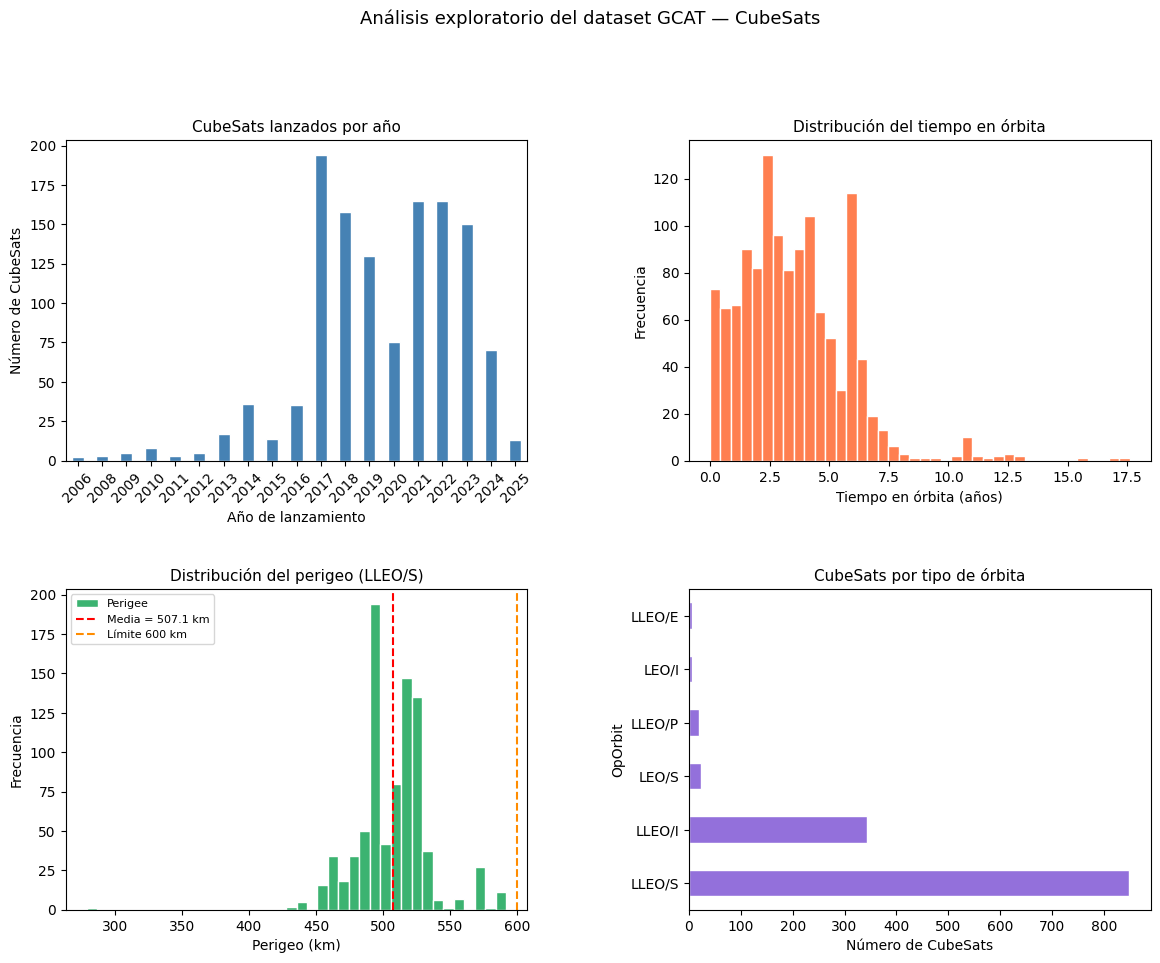

In [7]:
import matplotlib.gridspec as gridspec
import numpy as np

fig = plt.figure(figsize=(14, 10))
gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.4, wspace=0.35)

# Lanzamientos por año
ax1 = fig.add_subplot(gs[0, 0])
gcat_decay["LYear"].value_counts().sort_index().plot(kind="bar", ax=ax1,
    color="steelblue", edgecolor="white")
ax1.set_title("CubeSats lanzados por año", fontsize=11)
ax1.set_xlabel("Año de lanzamiento")
ax1.set_ylabel("Número de CubeSats")
ax1.tick_params(axis="x", rotation=45)

# Distribución del tiempo en órbita
ax2 = fig.add_subplot(gs[0, 1])
gcat_decay["tiempo_orbita_años"].dropna().plot.hist(bins=40, ax=ax2,
    color="coral", edgecolor="white")
ax2.set_title("Distribución del tiempo en órbita", fontsize=11)
ax2.set_xlabel("Tiempo en órbita (años)")
ax2.set_ylabel("Frecuencia")

# Distribución del perigeo (LLEO/S)
ax3 = fig.add_subplot(gs[1, 0])
perigeo_lleos = gcat_decay[gcat_decay["OpOrbit"] == "LLEO/S"]["Perigee"].dropna()
perigeo_lleos.plot.hist(bins=40, ax=ax3, color="mediumseagreen", edgecolor="white")
ax3.axvline(perigeo_lleos.mean(), color="red", linestyle="--",
    label=f"Media = {perigeo_lleos.mean():.1f} km")
ax3.axvline(600, color="darkorange", linestyle="--", label="Límite 600 km")
ax3.set_title("Distribución del perigeo (LLEO/S)", fontsize=11)
ax3.set_xlabel("Perigeo (km)")
ax3.set_ylabel("Frecuencia")
ax3.legend(fontsize=8)

# Distribución por tipo de órbita
ax4 = fig.add_subplot(gs[1, 1])
top_orbits = gcat_decay["OpOrbit"].value_counts().head(6)
top_orbits.plot(kind="barh", ax=ax4, color="mediumpurple", edgecolor="white")
ax4.set_title("CubeSats por tipo de órbita", fontsize=11)
ax4.set_xlabel("Número de CubeSats")

plt.suptitle("Análisis exploratorio del dataset GCAT — CubeSats", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

 ## Análisis del punto del perigeo en órbitas LLEO/S

#### Media

Vamos a observar las gráficas de los puntos de perigeo, el cual es el punto de la órbita más cercano a la Tierra y donde el satélite tendrá mayor velocidad, en todas las órbitas. Viendo que en nuestro dataset tenemos más datos de las órbitas del tipo LLEO/S (Lower Low Earth Orbit / Sun-Sync), es decir, son órbitas a una altura de 80km - 600km, con una inclinación de 95º - 104º y que son heliosincrónicas, esto es un tipo de órbita polar en la que el satélite pasa sobre cualquier punto de la Tierra siempre a la misma hora solar local.

En las gráficas, observaremos la densidad de un punto del perigeo en los diferentes tipos órbitas, además, podremos ver una recta vertical discontinua la cual representa la media del perigeo de las órbitas del tipo LLEO/S

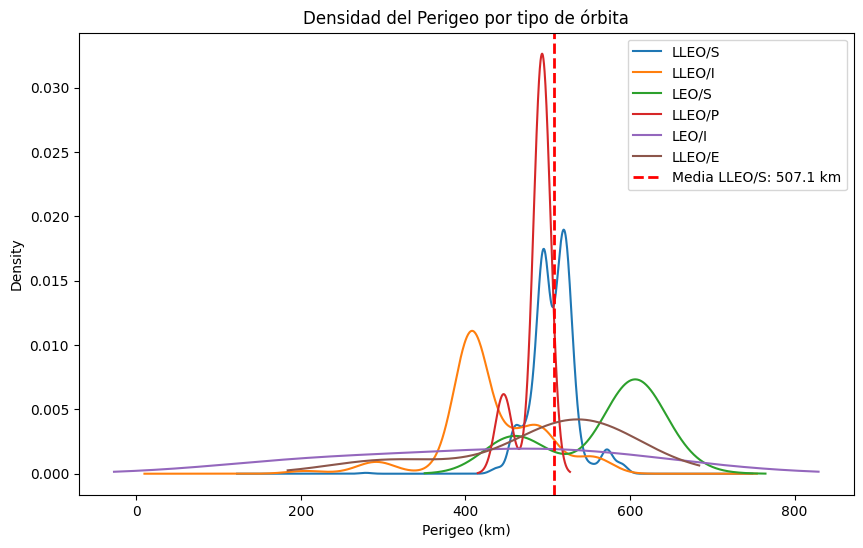

Media del perigeo en órbitas del tipo LLEO/S: 507.14504716981133


In [8]:
top_orbits = gcat_decay["OpOrbit"].value_counts().head(6).index
fig, ax = plt.subplots(figsize=(10, 6))
for orbit in top_orbits:
    subset = gcat_decay[gcat_decay["OpOrbit"] == orbit]["Perigee"].dropna()
    subset.plot.kde(ax=ax, label=orbit)

media_perigeo = gcat_decay.loc[gcat_decay['OpOrbit'] == 'LLEO/S', 'Perigee'].mean()
ax.axvline(media_perigeo, color='red', linestyle='--', linewidth=2, label=f'Media LLEO/S: {media_perigeo:.1f} km')

ax.legend()
ax.set_title("Densidad del Perigeo por tipo de órbita")
ax.set_xlabel("Perigeo (km)")
plt.show()

print(f"Media del perigeo en órbitas del tipo LLEO/S: {media_perigeo}")

Viendo esto, vamos a estudiar si el punto medio de perigeo en órbitas LLEO/S es significativamente menor de 600km, ya que "debido al problema inherente de los desechos espaciales, existen medidas políticas en curso para establecer la importancia de mitigarlos y eliminarlos. La directriz general es que las naves espaciales en órbita terrestre baja (LEO) deben desorbitar, también conocida como desintegración, o ser colocadas en una órbita cementerio dentro de un máximo de 25 años después de la finalización de su misión" [13.0 Sistemas de desorbitación - NASA](https://www.nasa.gov/smallsat-institute/sst-soa/deorbit-systems/#:~:text=The%20general%20guideline%20is%20that,of%20their%20mission%20(3).). 

Y sabiendo que, si se encuentran por debajo de los 600Km, podría regresar a la Tierra de forma natural en pocos años por efecto del arrastre atmosférico residual, mientras que a partir de los 600Km, [ese tiempo se extiende desde los 25 años hasta llegar a milenios](https://space-travel.blog/leo-roadmap-47d34e1a3fe1), si el perigeo medio de los CubeSats en órbitas LLEO/S se encuentra significativamente por debajo de 600Km, podemos concluir que la media de éstos han operado en la zona donde la reentrada natural está garantizada, siendo compatibles con las directrices internacionales de mitigación de debris (desechos).

Ahora, nos planteamos la pregunta ¿El punto medio de perigeo en órbitas LLEO/S es significativamente menor de 600km?

$H_0: \mu = 600;$ El tiempo medio en órbita en años es igual a 600Km

$H_A: \mu \lt 600;$ El tiempo medio en órbita es significativamente menor de 600Km

Con un nivel de Siginificación de $\alpha = 0.05$

Rechazando la hipótesis nula ($H_0$) para valores pequeños del estadístico.

No se trata de una distribución normal, pero dado al tamaño de la muestra, podemos hacer uso del Teorema del Límite Central.

In [9]:
muestra = gcat_decay[gcat_decay["OpOrbit"] == "LLEO/S"]["Perigee"]

mu0 = 600
xbar = muestra.mean()
cuasistd = muestra.std(ddof=1) # ddof divide entre n-1, para tener la cuasidesviación típica
n = len(muestra)

print(f"n = {n}")
print(f"Media = {xbar:.4f} km")
print(f"Cuasidesv. típica (S) = {cuasistd:.4f}")

#Estadístico de contraste
z = (xbar - mu0) / (cuasistd / math.sqrt(n))

print("Estadístico Z observado =", z)
p_valor = norm.cdf(z)

print(f"p_valor = {p_valor}")

n = 848
Media = 507.1450 km
Cuasidesv. típica (S) = 26.7229
Estadístico Z observado = -101.18583696598903
p_valor = 0.0


In [10]:
print(gcat_decay["LDate"].min())

2006-09-22 00:00:00


A la vista del resultado del p-valor, podemos decir que los datos de la muestra no son compatibles con la hipótesis de que la media del punto de perigeo no es significativamente menor de 600Km, es decir, si rechazásemos la hipótesis de que el punto medio del perigeo es igual a 600Km estaríamos cometiendo un error tipo I del ~0.00%, bastante menor del 5.00% permitido, por lo que podemos afirmar que el punto medio del perigeo es significativamente menor de los 600Km. 

Si el punto medio de perigeo fuera igual a 600Km la probabilidad de encontrar valores tan grandes es de 0.00, una probabilidad bastante pequeña, y por tanto, rechazamos la hipótesis de que el punto medio de perigeo es igual a 600Km.

In [11]:
alpha = 0.05

z_critico = norm.ppf(1 - alpha/2)
margen_error = z_critico * (cuasistd / math.sqrt(n))

ic_inf = xbar - margen_error
ic_sup = xbar + margen_error

print(f"IC bilateral 95%: [{ic_inf:.4f}, {ic_sup:.4f}] km")

IC bilateral 95%: [505.3465, 508.9436] km


La probabilidad de que el intervalo (506.25 - 509.25) contenga al verdadero valor del parámetro será del 95%, es decir, bastante por debajo de los 600Km.

Con esto, podemos afirmar que la media de los CubeSats que fueron lanzados desde el 21/02/2006 han operado en la zona donde la reentrada natural está garantizada, siendo compatibles con las directrices internacionales de mitigación de debris, cuya primera publicación fue el [15/10/2002.](https://www.unoosa.org/res/oosadoc/data/documents/2025/aac_105c_12025crp/aac_105c_12025crp_9_0_html/AC105_C1_2025_CRP09E.pdf)

#### Variabilidad

Ahora, vamos a ver si la variabilidad del perigeo en órbitas LLEO/S es significativamente mayor de 20, ya que los sistemas modernos de despliegue están diseñados para inyectar satélites en slots orbitales precisos (esto se refiere a la maniobra final donde un cohete/vehículo espacial libera el satélite en su trayectoria definitiva) con una dispersión de $\pm{10km}$, es decir, ${\sigma_0=20km}$. Por tanto, una desviación típica significativamente mayor de $20km$ nos estaría diciendo que los CubeSats de este dataset no han sido lanzados desde una plataforma única con control orbital preciso, luego procederían de múltiples lanzadores, vehículos y/o épocas distintas.[Advancements in the Epsilon Launch Vehicle’s Rideshare Capability and Future Missions.](https://digitalcommons.usu.edu/cgi/viewcontent.cgi?params=/context/smallsat/article/5285/&path_info=SSC22_XI_05.pdf) [Space Transportation. (Re)invented.](https://www.dorbit.space/media/3/65.pdf)

¿Es la variabilidad del perigeo en órbitas LLEO/S significativamente mayor de $20km$?

$H_0: \sigma = 20;$ La variabilidad del punto del perigeo en órbitas LLEO/S es igual a 20Km

$H_A: \sigma \gt 20;$ La variabilidad del punto del perigeo en órbitas LLEO/S es significativamente mayor de 20Km

Con un nivel de significación de $\alpha = 0.05$

Rechazando para valores grandes del estadístico.

In [12]:
muestra = gcat_decay[gcat_decay["OpOrbit"] == "LLEO/S"]["Perigee"].dropna()

n  = len(muestra)
s2 = muestra.var(ddof=1)
sigma0_2 = 20**2

chi2_stat = (n - 1) * s2 / sigma0_2

p_value = 1 - chi2.cdf(chi2_stat, df=n-1)

print(f"n = {n}")
print(f"Cuasivarianza S^2 = {s2:.4f}")
print(f"Chi^2 observado = {chi2_stat:.3f}")
print(f"p-valor = {p_value:.6f}")

n = 848
Cuasivarianza S^2 = 714.1123
Chi^2 observado = 1512.133
p-valor = 0.000000


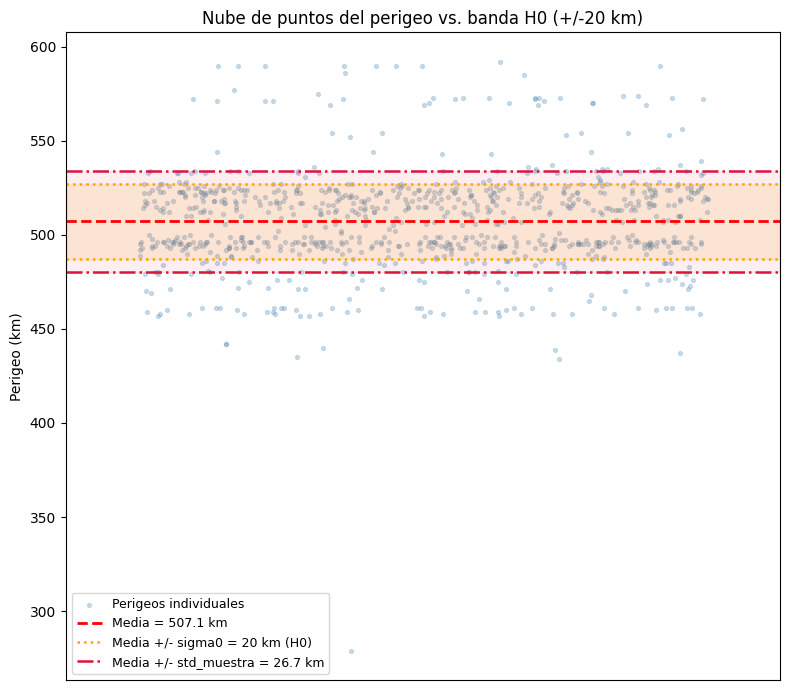

In [13]:

muestra = gcat_decay[gcat_decay["OpOrbit"] == "LLEO/S"]["Perigee"].dropna()

n = len(muestra)
xbar = muestra.mean()
s = muestra.std(ddof=1)
sigma0 = 20

np.random.seed(42)
jitter = np.random.uniform(-0.4, 0.4, size=n)

fig, ax = plt.subplots(figsize=(8, 7))

ax.scatter(jitter, muestra, alpha=0.25, s=8, color="steelblue", label="Perigeos individuales")

# Media
ax.axhline(xbar, color="red", linestyle="--", linewidth=2, label=f"Media = {xbar:.1f} km")

# Banda H0
ax.axhline(xbar + sigma0, color="orange", linestyle=":", linewidth=1.8, label=f"Media +/- sigma0 = 20 km (H0)")
ax.axhline(xbar - sigma0, color="orange", linestyle=":", linewidth=1.8)
ax.fill_between([-0.5, 0.5], xbar - sigma0, xbar + sigma0,
                color="orange", alpha=0.12)

# Banda real
ax.axhline(xbar + s, color="crimson", linestyle="-.", linewidth=1.8, label=f"Media +/- std_muestra = {s:.1f} km")
ax.axhline(xbar - s, color="crimson", linestyle="-.", linewidth=1.8)
ax.fill_between([-0.5, 0.5], xbar - s, xbar + s,
                color="crimson", alpha=0.07)

ax.set_xlim(-0.5, 0.5)
ax.set_xticks([])
ax.set_ylabel("Perigeo (km)")
ax.set_title("Nube de puntos del perigeo vs. banda H0 (+/-20 km)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

Con un margen de error del 5% o incluso del 1% podemos asegurar que la variabilidad del perigeo es significativamente mayor de 20Km. La compatibilidad entre la $H_0$ y nuestros datos es del ~0.00%, luego podemos afirmar que la variabilidad del perigeo en órbitas LLEO/S es significativamente mayor de 20Km. Y, por tanto, podemos afirmar que los datos proceden de múltiples lanzadores, vehículos y/o épocas distintas. 

Si rechazásemos la hipótesis de que la variabilidad del perigeo es igual a 20Km, estaríamos cometiendo un error del tipo I del 0.00%, por debajo incluso del 1%, por lo que podemos afirmar que la variabilidad del perigeo es significativamente mayor de 20Km.

## Tiempo en órbita

Los CubeSats 1U (10×10×10 cm, hasta 1.33kg) y 6U (10×20×30 cm, hasta 12kg) presentan diferencias en su coeficiente balístico [$B=(C_D*{S})/m$](https://riunet.upv.es/server/api/core/bitstreams/97ff542a-42d4-4a32-a97a-10c78c48379b/content), donde $m$ es la masa, $C_D$ es el coeficiente de arrastre y $S$ la sección transversal. El coeficiente balístico es el factor principal que determina la velocidad a la que el satélite pierde altitud y es atraído de vuelta a la Tierra, por tanto, un menor coeficiente balístico implicaría que el CubeSats tiene menos fricción (menor efecto de arrastre atmosférico) y mantendría su órbita por más tiempo. 

Dado que los 6U tienen mayor masa pero una sección transversal proporcionalmente menor respecto a su masa que los 1U, es decir, la masa aumenta hasta 9 veces y la sección transversal de 2 a 6 (de $100cm^2$ a un rango de $200-600cm^2$), se espera que presenten un coeficiente balístico mayor los 1U que los 6U y, en consecuencia, un tiempo medio en órbita menor. Vamos a contrastar si esta diferencia es estadísticamente significativa.

Nos planteamos, ¿el tiempo medio en órbita en los CubeSats 6U es mayor que el de los 1U?

$H_0: \mu_{6U} - \mu_{1U} = 0;$ El tiempo medio en órbita en años es igual en los CubeSats 6U y 1U

$H_A: \mu_{6U} - \mu_{1U} \gt 0;$ El tiempo medio en órbita en CubeSats 6U es significativamente mayor que el de los 1U

Con un nivel de significación de $\alpha=0.05$

Rechazando para valores grandes del estadístico

In [14]:
u1 = gcat_decay[gcat_decay["Bus"].str.contains(r"\b1U\b", case=False, na=False)]["tiempo_orbita_años"]
u6 = gcat_decay[gcat_decay["Bus"].str.contains(r"\b6U\b", case=False, na=False)]["tiempo_orbita_años"]

x1 = u6.mean()
x2 = u1.mean()   
s1 = u6.std(ddof=1)
s2 = u1.std(ddof=1)
n1 = len(u6)
n2 = len(u1)

print(f"6U -> n={n1}, media={x1:.2f} años, S={s1:.2f}")
print(f"1U -> n={n2}, media={x2:.2f} años, S={s2:.2f}")

z = (x1 - x2) / np.sqrt(s1**2/n1 + s2**2/n2)

p_value = 1 - norm.cdf(z)

print(f"\nEstadístico Z = {z:.4f}")
print(f"p-valor = {p_value:.6f}")

6U -> n=183, media=3.05 años, S=1.70
1U -> n=184, media=2.95 años, S=3.15

Estadístico Z = 0.3809
p-valor = 0.351648


C:\Users\diego\AppData\Local\Temp\ipykernel_46288\2255855746.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([u1.dropna(), u6.dropna()], labels=["1U", "6U"], patch_artist=True,


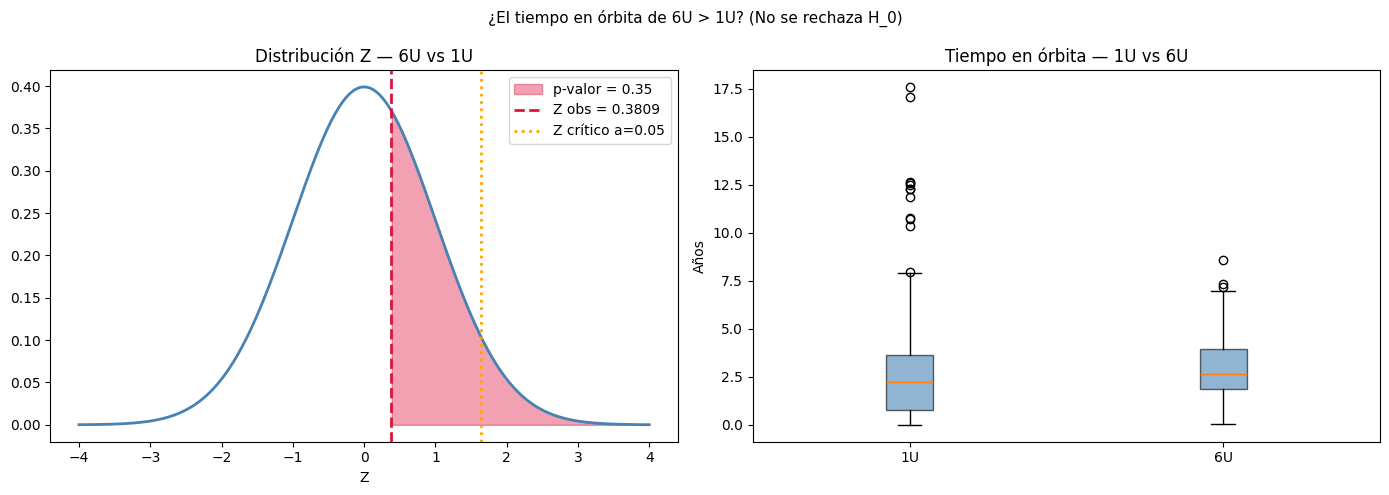

In [15]:
x = np.linspace(-4, 4, 1000)
y = norm.pdf(x)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribución Z
axes[0].plot(x, y, color="steelblue", linewidth=2)
axes[0].fill_between(x, y, where=(x >= z), color="crimson", alpha=0.4, label=f"p-valor = 0.35")
axes[0].axvline(z, color="crimson", linestyle="--", linewidth=2, label=f"Z obs = {z:.4f}")
axes[0].axvline(norm.ppf(0.95), color="orange", linestyle=":", linewidth=2, label="Z crítico a=0.05")
axes[0].set_title("Distribución Z — 6U vs 1U")
axes[0].set_xlabel("Z")
axes[0].legend()

# Boxplot comparativo
axes[1].boxplot([u1.dropna(), u6.dropna()], labels=["1U", "6U"], patch_artist=True,
                boxprops=dict(facecolor="steelblue", alpha=0.6))
axes[1].set_title("Tiempo en órbita — 1U vs 6U")
axes[1].set_ylabel("Años")

plt.suptitle("¿El tiempo en órbita de 6U > 1U? (No se rechaza H_0)", fontsize=11)
plt.tight_layout()
plt.show()

Viendo el resultado del p_valor, nos indica una compatibilidad de los datos con la hipótesis de que la diferencia el tiempo medio en órbita del tipo 1U de CubeSat con el tipo 6U es del ~35.16%, por lo que no nos podemos permitir rechazar la $H_0$. Si rechazásemos la $H_0$ estaríamos cometiendo un error tipo I del ~35.16%, bastante mayor del 5.00% permitido, por lo que no podemos afirmar que el tiempo medio en órbita de los CubeSats 6U sea significativamente mayor que el de los 1U. 

Por tanto, concluimos que el tiempo medio en órbita de los CubeSats 6U no es significativamente mayor que el de los 1U.

#### ¿Cómo se distribuye?

Acabamos de contrastar el tiempo medio en órbita en años entre los CubeSats 1U y 6U. Ahora, vamos a ver cómo se distribuye esta variable.

Viendo la gráfica, podemos ver que tiene una asimetría bastante clara hacia la derecha. La mayoría de los CubeSats permanecen en órbita entre 1 y 5 años, y hay una minoría que supera los 8 años. Esto nos indica que se podría distribuir como una distribución Gamma.

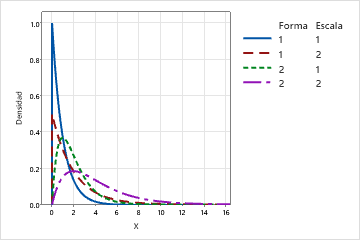

*Ejemplo de distribución Gamma*

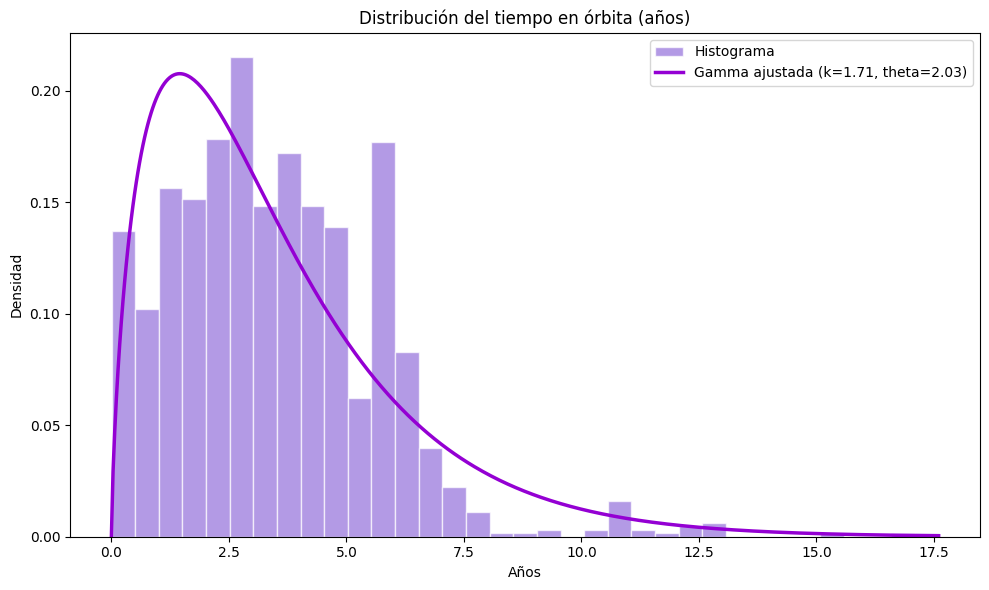

In [16]:
x = gcat_decay["tiempo_orbita_años"]

# Ajuste Gamma:
# floc=0 fuerza la distribución a empezar en 0
shape, loc, scale = gamma.fit(x, floc=0)

# Histograma normalizado para comparar con la densidad
fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(
    x,
    bins=35,
    density=True,
    color="mediumpurple",
    edgecolor="white",
    alpha=0.7,
    label="Histograma"
)

# Curva Gamma ajustada
x_fit = np.linspace(0, x.max(), 500)
y_fit = gamma.pdf(x_fit, a=shape, loc=loc, scale=scale)

ax.plot(
    x_fit,
    y_fit,
    color="darkviolet",
    linewidth=2.5,
    label=f"Gamma ajustada (k={shape:.2f}, theta={scale:.2f})"
)

ax.set_title("Distribución del tiempo en órbita (años)")
ax.set_xlabel("Años")
ax.set_ylabel("Densidad")
ax.legend()

plt.tight_layout()
plt.show()

Por tanto, nos preguntamos ¿el tiempo en órbita en años de un CubeSat se distribuye por una distibución Gamma(1.78, 1.84)?

Como lo queremos contrastar a una distribución continua y los datos que tenemos son mayores que 30, vamos a utilizar el contraste de Kolmogorov-Smirnov.

$H_0$: el tiempo en órbita sigue una distribución Gamma(a=1.78, b=1.84)

$H_A$: el tiempo en órbita no sigue dicha distribución

Con un nivel de significación de $\alpha=0.05$

Sabiendo que el estadístico es $D_n = sup|F_n(x) - F_0(x)|$, rechazaremos para valores grandes del estadístico, ya que esto nos está diciendo la discrepancia de nuestros datos con la distribución.

(1248, 45)
Parámetros reestimados: k=1.7147, theta=2.0340
Estadístico D = 0.094505
p-valor       = 0.000000


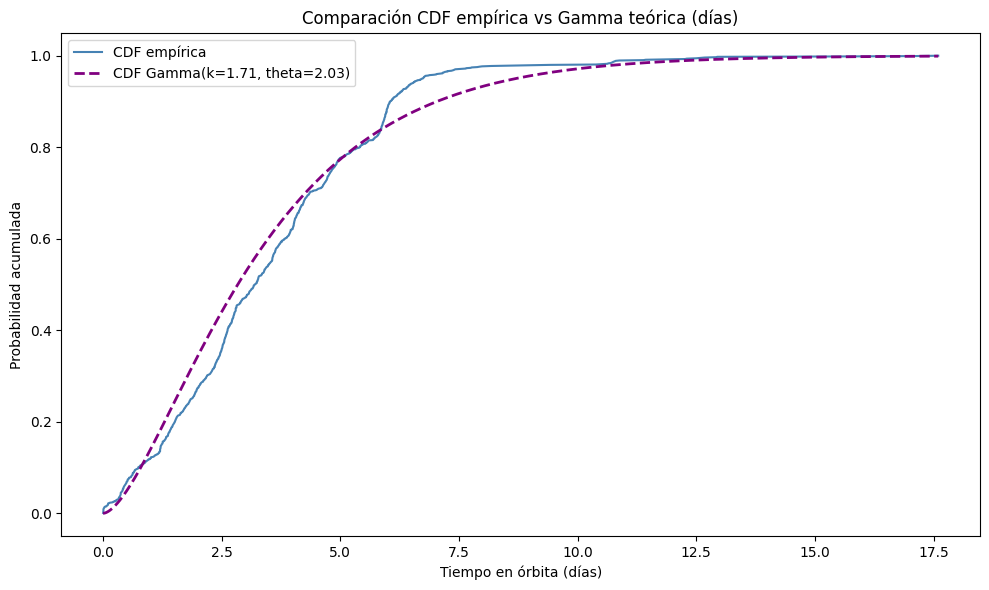

In [17]:
print(gcat_decay.shape)
datos = gcat_decay["tiempo_orbita_años"]

k, loc, theta = gamma.fit(datos, floc=0)
print(f"Parámetros reestimados: k={k:.4f}, theta={theta:.4f}")

# Test KS
D, p_value = kstest(datos, "gamma", args=(k, 0, theta))
print(f"Estadístico D = {D:.6f}")
print(f"p-valor       = {p_value:.6f}")

# Gráfico de probabilidad acumulada (CDF empírica vs teórica)
fig, ax = plt.subplots(figsize=(10, 6))

# CDF empírica
datos_sorted = np.sort(datos)
cdf_empirica = np.arange(1, len(datos_sorted) + 1) / len(datos_sorted)
ax.plot(datos_sorted, cdf_empirica, label="CDF empírica", color="steelblue", linewidth=1.5)

# CDF teórica
x = np.linspace(0, datos_sorted.max(), 1000)
cdf_teorica = gamma.cdf(x, a=k, loc=0, scale=theta)
ax.plot(x, cdf_teorica, label=f"CDF Gamma(k={k:.2f}, theta={theta:.2f})", 
        color="purple", linewidth=2, linestyle="--")

ax.set_title("Comparación CDF empírica vs Gamma teórica (días)")
ax.set_xlabel("Tiempo en órbita (días)")
ax.set_ylabel("Probabilidad acumulada")
ax.legend()
plt.tight_layout()
plt.show()

El test KS obtiene $D=0.0702$ con $p_{valor}\approx 0$, por lo que rechazamos la hipótesis de que el tiempo en órbitas en años de un CubeSat se distribuye por una Gamma(1.78, 1.84) al nivel de significación del 5%. Sin embargo, observando la gráfica de CDF, el ajuste es visualmente bueno en la mayor parte del rango (0-6 años), con la principal desviación en la zona de 7-8 años, donde la distribución empírica supera a la teórica. Este rechazo es puede darse por el elevado tamaño muestral (n = 1248), ya que con tanta información el test puede detecta desviaciones mínimas que serían irrelevantes en la práctica. 

Por tanto, podríamos concluir que estadísticamente habría que rechazar la $H_0$, pero en la práctica parece que la Gamma descrita es una aproximación razonable del tiempo en órbita en años de un CubeSat, especialmente para el rango de 0 a 6 años.

#### Los 3 tipos más frecuentes

Anteriormente contrastamos si el tiempo medio en órbita en años de los CubaSats 6U era significativamente mayor que el de los 1U, y obtuvimos que no existían diferencias significativas entre ambos grupos. Lo que me lleva a preguntarme si ocurre lo mismo al ampliar la comparación para 3 grupos de forma simultánea, es decir, para los 1U, 3U y 6U.

Llevándonos a la siguiente pregunta, ¿el tiempo en órbita medio/mediana de los Cubesats 3U, 1U, 6U difieren significativamente?

1U: n=184, mediana=2.25 años, media=2.95 años
3U: n=881, mediana=3.60 años, media=3.69 años
6U: n=183, mediana=2.67 años, media=3.05 años


C:\Users\diego\AppData\Local\Temp\ipykernel_46288\3525505428.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


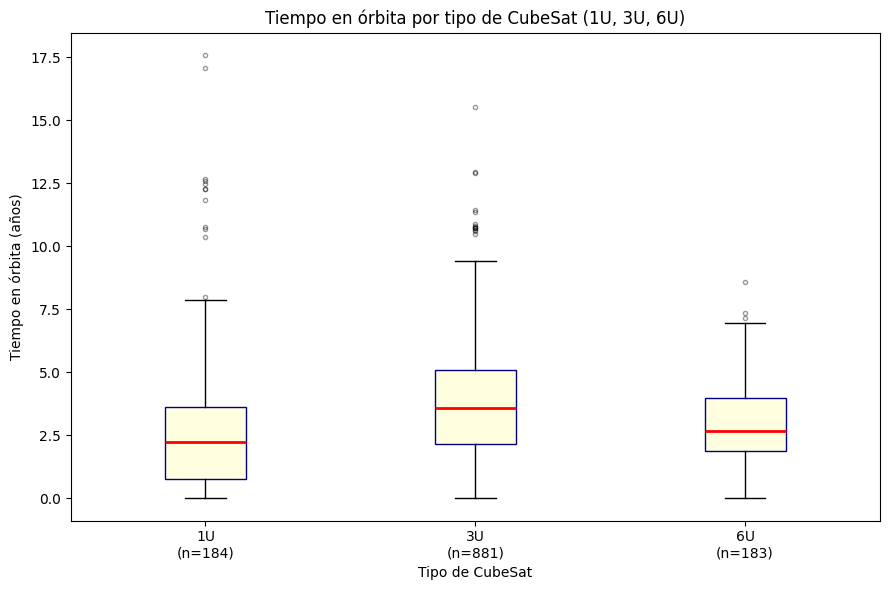

In [18]:
# Filtramos los 3 grupos
grupos = {
    "1U": gcat_decay[gcat_decay["Bus"].str.contains(r"\b1U\b", case=False, na=False)]["tiempo_orbita_años"],
    "3U": gcat_decay[gcat_decay["Bus"].str.contains(r"\b3U\b", case=False, na=False)]["tiempo_orbita_años"],
    "6U": gcat_decay[gcat_decay["Bus"].str.contains(r"\b6U\b", case=False, na=False)]["tiempo_orbita_años"],
}

for nombre, datos in grupos.items():
    print(f"{nombre}: n={len(datos)}, mediana={datos.median():.2f} años, media={datos.mean():.2f} años")

# Boxplot
fig, ax = plt.subplots(figsize=(9, 6))
ax.boxplot(
    [g.values for g in grupos.values()],
    labels=[f"{k}\n(n={len(v)})" for k, v in grupos.items()],
    patch_artist=True,
    boxprops=dict(facecolor="lightyellow", color="navy"),
    medianprops=dict(color="red", linewidth=2),
    flierprops=dict(marker="o", markersize=3, alpha=0.4)
)
ax.set_title("Tiempo en órbita por tipo de CubeSat (1U, 3U, 6U)")
ax.set_xlabel("Tipo de CubeSat")
ax.set_ylabel("Tiempo en órbita (años)")
plt.tight_layout()
plt.show()

Viendo los boxplots de los 3 tipos de CubeSats, parece que no difieren demasiado entre ellos, pero vamos a asegurarnos haciendo un contraste para más de 2 muestras que son independientes entre sí. Para ello vamos a utilizar el contraste de Kruskal-Wallis, que nos sirve para muestras independientes entre sí, las cuales pueden tener diferentes tamaños muestrales.

Volviendo a la pregunta del contraste, ¿el tiempo en órbita medio/mediana de los Cubesats 3U, 1U, 6U difieren significativamente? 

Planteamos las hipótesis:

$H_0: \mu_{1U}=\mu_{3U}=\mu_{6U}$; el tiempo en órbita de los 3 tipos de CubeSats procede de la misma población

$H_A: \mu_{i}\ne\mu_{j}$; el tiempo en órbita de al menos 1 tipo de CubeSat difiere significativamente del resto de tipos de CubeSats

Con un nivel de significación de $\alpha=0.05$

Dado que el estadístico sigue la siguiente fórmula: $$H=\frac{12}{n(n+1)}\sum_{i=1}^{k}{\frac{R_i^2}{n_i}}-3(n+1)\rightarrow\chi^2_{k-1}$$
Eso si $H_0$ es cierta, por tanto rechazaremos para valores grandes del estadístico.

In [19]:
u1 = gcat_decay[gcat_decay["Bus"].str.contains(r"\b1U\b", case=False, na=False)]["tiempo_orbita_años"]
u3 = gcat_decay[gcat_decay["Bus"].str.contains(r"\b3U\b", case=False, na=False)]["tiempo_orbita_años"]
u6 = gcat_decay[gcat_decay["Bus"].str.contains(r"\b6U\b", case=False, na=False)]["tiempo_orbita_años"]

print(f"1U: n={len(u1)}, mediana={u1.median():.2f}, media={u1.mean():.2f}")
print(f"3U: n={len(u3)}, mediana={u3.median():.2f}, media={u3.mean():.2f}")
print(f"6U: n={len(u6)}, mediana={u6.median():.2f}, media={u6.mean():.2f}")

H, p_value = kruskal(u1, u3, u6)

print(f"\nEstadístico H = {H:.4f}")
print(f"p-valor = {p_value:.6f}")

1U: n=184, mediana=2.25, media=2.95
3U: n=881, mediana=3.60, media=3.69
6U: n=183, mediana=2.67, media=3.05

Estadístico H = 55.1656
p-valor = 0.000000


El p_valor indica una compatibilidad de los datos con la hipótesis de que el tiempo en órbita de los 3 tipos de CubeSats procedan de la misma población es del ~0.00% por lo que nos podemos permitir rechazar la $H_0$. Si rechazásemos la $H_0$ estaríamos cometiendo un error tipo I del ~0.00%, prácticamente nula, por lo que podemos afirmar que la población del tiempo en órbita de 1 tipo de CubeSat difiere significativamente con otro tipo de CubeSat.

Ahora vamos a ver qué pareja de CubeSats difieren significativamente en cuanto a su tiempo medio en órbita en años. Para ello vamos a utilizar el contraste U de Mann-Whitney.

$H_0: Me_i=Me_j;$ El tiempo en órbita de los CubeSats del tipo i se distribuye igual que los del tipo j

$H_A: Me_i\ne Me_j;$ El tiempo en órbita de los CubeSats del tipo i se distribuye de forma distinta que los del tipo j

Con un nivel de significación de $\alpha=\frac{0.05}{3} = 0.0167$, aplicando la corrección de Bonferroni.

El estadístico U, tomará valores grandes si hay diferencias pequeñas entre las poblaciones; por otro lado, si las diferencias son grandes tomará valores pequeños, es decir, cuanto más pequeño es el valor de U, más improbable es la igualdad entre los 2 grupos; por tanto, rechazaremos para valores pequeños del estadístico.

In [20]:

U, p = mannwhitneyu(u1, u3, alternative='two-sided')
print("------------------")
print("---  1U vs 3U  ---")
print(f"U = {U}")
print(f"p-valor = {p:.6f}")
print("\n")

print("------------------")
print("---  1U vs 6U  ---")
U, p = mannwhitneyu(u1, u6, alternative='two-sided')
print(f"U = {U}")
print(f"p-valor = {p:.6f}")
print("\n")

print("------------------")
print("---  3U vs 6U  ---")
U, p = mannwhitneyu(u3, u6, alternative='two-sided')
print(f"U = {U}")
print(f"p-valor = {p:.6f}")

------------------
---  1U vs 3U  ---
U = 55544.0
p-valor = 0.000000


------------------
---  1U vs 6U  ---
U = 13449.0
p-valor = 0.000860


------------------
---  3U vs 6U  ---
U = 95742.0
p-valor = 0.000063


Todos los p_valores indican una compatibilidad de los datos con la hipótesis de que la distribución del tiempo medio en órbita del tipo i de CubeSat y la del tipo j sean iguales es del ~0.00% por lo que nos podemos permitir rechazar la $H_0$ para todos los casos. Si rechazásemos la $H_0$ estaríamos cometiendo un error tipo I del ~0.00%, prácticamente nula, por lo que podemos afirmar que la distribución del tiempo medio en órbita de 1 tipo de CubeSat difiere significativamente los otros 2 tipos de CubeSats. 

Por tanto, podemos concluir que el tiempo en órbita en años de los 3 tipos de CubeSats se distribuyen de forma significativamente diferente. Como podemos ver el los boxplots, el tiempo en órbita del CubeSat va perdiendo homogeneidad a medida que aumenta su peso y tamaño, el tiempo en órbita de los CubeSats 6U tienen mayor homogeneidad que los del tipo 1U. Esto puede deberse a que los tipo 1U permanezcan menos tiempo en órbita, pero hay algunos que tienen tiempos más largos, lo que hace que su distribución vaya teniendo una asimetría hacia la derecha más pronunciada que los del tipo 6U.

siendo los de 3U los que mayor tiempo de permanencia tienen, con una mediana de 3.60

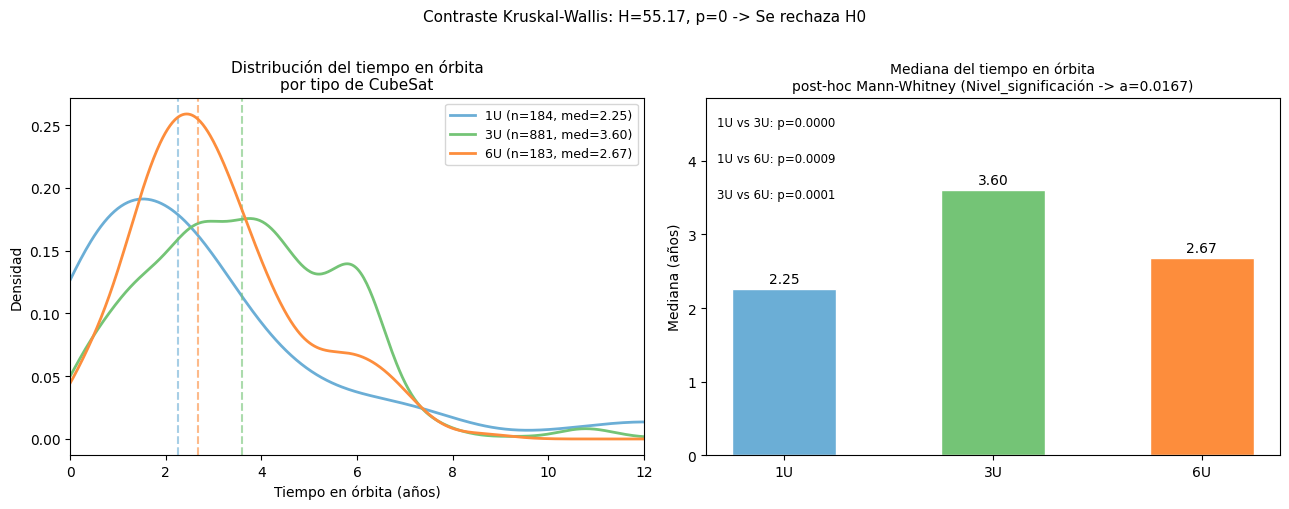

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colores = {"1U": "#6BAED6", "3U": "#74C476", "6U": "#FD8D3C"}
grupos = {"1U": u1, "3U": u3, "6U": u6}

# Panel izq: KDE comparativa
ax = axes[0]
for nombre, grupo in grupos.items():
    grupo.plot.kde(ax=ax, label=f"{nombre} (n={len(grupo)}, med={grupo.median():.2f})",
                  color=colores[nombre], linewidth=2)
    ax.axvline(grupo.median(), color=colores[nombre], linestyle="--", alpha=0.6)

ax.set_title("Distribución del tiempo en órbita\npor tipo de CubeSat", fontsize=11)
ax.set_xlabel("Tiempo en órbita (años)")
ax.set_ylabel("Densidad")
ax.legend(fontsize=9)
ax.set_xlim(0, 12)

# Panel der: Medianas con anotación de pares significativos
ax2 = axes[1]
nombres = list(grupos.keys())
medianas = [g.median() for g in grupos.values()]
bars = ax2.bar(nombres, medianas, color=list(colores.values()), edgecolor="white", width=0.5)
for bar, val in zip(bars, medianas):
    ax2.text(bar.get_x() + bar.get_width()/2, val + 0.05,
             f"{val:.2f}", ha="center", va="bottom", fontsize=10)

for i, (par, p_val) in enumerate([("1U vs 3U", 0.0), ("1U vs 6U", 0.00086), ("3U vs 6U", 0.000063)]):
    ax2.annotate(f"{par}: p={p_val:.4f} ", xy=(0.02, 0.92 - i*0.10),
                 xycoords="axes fraction", fontsize=8.5)

ax2.set_title("Mediana del tiempo en órbita\npost-hoc Mann-Whitney (Nivel_significación -> a=0.0167)", fontsize=10)
ax2.set_ylabel("Mediana (años)")
ax2.set_ylim(0, max(medianas) * 1.35)

plt.suptitle("Contraste Kruskal-Wallis: H=55.17, p=0 -> Se rechaza H0", fontsize=11, y=1.01)
plt.tight_layout()
plt.show()

---

#### Modelo regresivo para el tiempo en órbita

Ahora, vamos a hacer un modelo regresivo para predecir el tiempo en órbita en años de un CubeSat.

El arrastre atmosférico es una de las variables a tener en cuenta, ya que la degradación orbital aumenta de forma notable. Por tanto, podríamos decir que el arrastre atmosférico es una de las principales variables en el cálculo del tiempo en órbita del CubeSat, pero esta es una varible que no podemos calcular; sin embargo, podríamos decir que el punto del perigeo y apogeo son variables a tener en cuenta para el tiempo en órbita del CubeSat, ya que tiene relación con la degradación orbital, que a su vez la tiene con el arrastre atmosférico. Además de que, como vimos en el primer contraste, los CubeSats están orbitanto de forma significativa por debajo de los 600Km, viendo el intervalo de confianza (506.25 - 509.25) el cual contendrá al verdadero valor del parámetro con una confianza del 95%, a esta altitud el arrastre atmosférico no es despreciable; es por eso que pienso que las variables de perigeo y apogeo pueden ser significativas para el modelo.

Por otra parte, sabiendo cómo funciona el coeficiente balístico, podemos afirmar que a cuanta mayor masa, mayor inercia frente al arrastre, lo que nos lleva a un mayor tiempo en órbita del satélite. Por tanto, es probable que la masa pueda tener un efecto sobre el tiempo en órbita del CubeSat.

Con esta base, podemos crear un primer modelo de regresión para predecir el tiempo en órbita del CubeSat en función de: la altura del perigeo y del apogeo, la inclinación de la órbita (Inc), la masa, el año de lanzamiento(LYear) y el tipo de CubeSat (Bus)

Todo esto lo vamos a hacer solo fijándonos en los CubeSats contrastados anteriormente, es decir, 1U, 3U y 6U.

In [22]:
variables = ["tiempo_orbita_años", "Perigee", "Apogee", "Inc", "Mass", "Bus", "LYear"]

df_model = gcat_decay[gcat_decay["Bus"].str.contains(r"\b(1U|3U|6U)\b", case=False, na=False)][variables].dropna()

# Extraemos el tipo de bus limpio (1U, 3U, 6U)
df_model["Bus"] = df_model["Bus"].str.extract(r"\b(1U|3U|6U)\b", expand=False)

df_model = df_model.reset_index(drop=True)

# Convertimos la variable categórica en dummie cogiendo el tipo 1U como referencia
dummies = pd.get_dummies(df_model["Bus"], prefix="Bus", drop_first=False, dtype=float).drop(columns=["Bus_1U"])
dummies = dummies.reset_index(drop=True)

x_train = df_model[["Perigee", "Apogee", "Inc", "Mass", "LYear"]].join(dummies)
x_train = sm.add_constant(x_train)  # añadimos el intercept del modelo (columna de 1s)

y_train = df_model["tiempo_orbita_años"]

modelo = sm.OLS(endog=y_train, exog=x_train)
modelo = modelo.fit()
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:     tiempo_orbita_años   R-squared:                       0.676
Model:                            OLS   Adj. R-squared:                  0.674
Method:                 Least Squares   F-statistic:                     370.0
Date:                Thu, 28 May 2026   Prob (F-statistic):          2.44e-298
Time:                        13:47:00   Log-Likelihood:                -2087.5
No. Observations:                1248   AIC:                             4191.
Df Residuals:                    1240   BIC:                             4232.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        986.7456     25.247     39.083      0.0

C:\Users\diego\AppData\Local\Temp\ipykernel_46288\3378269165.py:3: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_model = gcat_decay[gcat_decay["Bus"].str.contains(r"\b(1U|3U|6U)\b", case=False, na=False)][variables].dropna()


Tras realizar el modelo, podemos observar que ni la masa del CubeSat ni el tipo del mismo son variables significativas en la predicción del tiempo en órbita del satélite. Los datos no muestran evidencia de un efecto significativo de estas variable sobre el tiempo en órbita en años; el efecto que tiene es perfectamente atribuible al azar. En caso de estar diciendo que la masa tiene un efecto significativo sobre el tiempo en órbita en años del CubeSat, nos estaríamos equivocando en el 77.9% de las veces, por tanto, podemos afirmar que dicha variable no tiene un efecto signnificativo sobre el tiempo en órbita en años del CubeSat.

Sin embargo, el perigeo, apogeo, la inclinación y el año de lanzamiento, a la vista de su p_valor, podemos ver que tienen un efecto significativo en la variable endógena. Si dijésemos que tienen un efecto significativo, nos estaríamos equivocando en un ~0.00% de las veces, lo que nos lleva a afirmar que tienen un efecto significativo. Es decir, los datos muestran evidencia de un efecto significativo de estas variables sobre la variable endógena.

Por otra parte, podemos ver que por el contraste F de significación del modelo, que obtenemos un p_valor ~0.00, lo que nos dice que los datos evidencian que el modelo es significativo en su conjunto, y la probabilidad de cometer error al decir que el modelo no es significativo en su conjunto es prácticamente nula.

Ahora, vamos a crear el modelo pero sin las variables que no tienen un efecto significativo sobre la variable endógena, es decir, la masa y el tipo de CubeSat. Con esto, vamos a ver si mejora la precisión del modelo, en cuyo caso tendrían un efecto contrario, si sigue igual y que realmente no aportaban nada, o si empeora, dando lugar a que tuviera efecto teniendo relación con otra variable.

In [23]:
variables = ["tiempo_orbita_años", "Perigee", "Apogee", "Inc", "LYear"]

df_model = df_model.reset_index(drop=True)

x_train = df_model[["Perigee", "Apogee", "Inc", "LYear"]]
x_train = sm.add_constant(x_train)  # añadimos el intercept del modelo (columna de 1s)

y_train = df_model["tiempo_orbita_años"]

modelo = sm.OLS(endog=y_train, exog=x_train)
modelo = modelo.fit()
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:     tiempo_orbita_años   R-squared:                       0.675
Model:                            OLS   Adj. R-squared:                  0.674
Method:                 Least Squares   F-statistic:                     644.2
Date:                Thu, 28 May 2026   Prob (F-statistic):          3.86e-301
Time:                        13:47:00   Log-Likelihood:                -2090.6
No. Observations:                1248   AIC:                             4191.
Df Residuals:                    1243   BIC:                             4217.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        984.1874     24.831     39.636      0.0

Viendo esto, podemos afirmar que las variables eliminadas no proporcionaban ningún tipo de efecto sobre la variable endógena, ya que el modelo no ha mejorado, lo podemos ver en el valor de $R^2$, el cual representa la proporción de la variabilidad del tiempo en órbita en años por la variabilidad de las variables explicativas (perigeo, apogeo, inclinación y año de lanzamiento). A su vez, este valor nos da una representación de qué tan bueno es el modelo, $0\le{R^2}\le1$ y nuestro modelo ha salido de $R^2=0.657$n un valor relativamente bueno.

Por otra parte, podemos ver que el tiempo en órbita no se distribuye por una distribución normal, ya que el p_valor de Omnibus es de 0.00. Es decir, si estuviéramos diciendo que el tiempo en órbita en años no se disstribuye por una normal, estaríamos cometiendo un error de tipo I del 0.00%, es por ello que podemos afirmar que no se ditribuye por una distribución normal. Además, viendo la simetría (-1.09) y la kurtosis (9.72), podemos ver que tampoco se parece a una normal, ya que si se distribuyera o su distribución no fuera significativamente diferente a la de una distribución normal, tendría una simetría de $\approx0$ y una kurtosis de $\approx3$.

## Conclusión

Con este análisis hemos podido ver y confirmar que el perigeo medio de los CubeSats en órbitas LLEO/S está significativamente por debajo de los 600Km, por lo que todos los CubeSats que ya fueron lanzados han cumplido con las directrices internacionales de mitigación de debris.

Además, la variabilidad de dicho punto es significativamente mayor de 20Km, por lo que pudimos demostrar que estos datos procedían de varios lanzadores, vehículos o épocas distintas; algo coherente ya que se suelen lanzar o como despliegue desde la ISS o desde un lanzador dedicado o compartido.

Como pudimos ver, la distribución del tiempo en órbita en años, se parecía a una Gamma(1.78, 1.84), pero estadísticamente, por el contraste de Kolmogorov-Smirnov, hemos podido observar que no se distribuye por dicha distribución Gamma, pero que esto puede deberse al elevado tamaño muestral (n=1248).

Por otra parte, ha quedado demostrado que la distribución del tiempo en órbita es diferente en los 3 tipos de CubeSats más frecuentes, pero que esto podría derivar de que hay una parte de los CubeSats 1U que permanecen más tiempo en órbita mientra que hay otros que permanecen menos tiempo, haciendo que su ditribución sea menos homogénea y con una asimetría hacia la derecha mayor que los 6U. Por tanto, hay más variabilidad de tiempo en órbita en los 1U que los 6U. Y por lo que parece, a cuanto mayor unidades de CubeSats (1U es una unidad y 6U son 6 unidades), hay una mayor variabilidad en el tiempo en órbita en años. No obstante, pudimos ver e+por un contraste paramétrico de diferencia de medias que el tiempo medio en órbita en años de los 1U no difiere significativamente de los del tipo 6U.

A su vez, el modelo de regresión para la variable endógena tiempo en órbita en años, se puede llegar a explicar a través del perigeo, apogeo, la inclinación y el año de lanzamiento con una variabilidad del 65.6%.

Con todo esto, he podido ver que, a pesar de que parezca que lanzan satélites "sin pensar", hay directrices que regulan la mitigación de los desechos espaciales y que cada satélite que han lanzado desde el año 2006 ha seguido y cumplido dichas regulaciones. Aunque el número de satélites lanzados esté creciendo exponencialmente, todos ellos lo hacen siguiendo unas prevenciones; no obstante, hay que tener en cuenta de que también se debería de controlar el número de satélites lanzados por una entidad; ya que, a pesar de que tengan un límite de tiempo de órbita para que no se conviertan en desechos y se mantengan ahí pudiendo provocar colisiones con otros satélites, actualmente lanzar un satélite parece que no es tan "complicado" con la aparición de los satélites de tamaño pequeño.

## Referencias adicionales

[General Catalog of Artificial Space Object](https://planet4589.org/space/gcat)

[Low Earth Orbit Visualization](https://platform.leolabs.space/visualization)

[Reporte del medioambiente espacial de la ESA, 2025](https://www.esa.int/Space_Safety/Space_Debris/ESA_Space_Environment_Report_2024)